---
title: "Engines, Refrigerators and Carnot — Level 2"
short_title: "04 Engines & Refrigerators"
numbering:
  heading_2: true
  equation: true
---

# Engines, Refrigerators and Carnot

:::{seealso} Math for this topic
- [T-M3: Exact differentials and thermodynamic calculus](../math/03-thermodynamic-calculus.ipynb)
- [M3: Multivariable calculus](../../level2-book/math/03-multivariable-calculus.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 20 | Efficiency calculations for given cycles |
| **2** | **Schroeder, ch. 4** | **Real engines, Otto and Diesel cycles, the Carnot bound derived from entropy** |
| 3 | Pathria, ch. 1 | Irreversibility and fluctuation theorems (partly beyond Pathria) |

The new skill at this level: deriving efficiency limits from the second law, then seeing how far real cycles fall short and why

Math for this topic: T-M3 (exact differentials and line integrals) and mechanics M3 (partial derivatives).
:::

Workbook example ladder: Carnot efficiency → an Otto cycle with a real gas → bounds on extractable work. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Free Energy, Chemical Potential and Phase Equilibria](05-free-energy-phase-equilibria.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **Heat Engines and the Carnot Bound**

   An engine runs between 600 K and 300 K.

   (a) Find its maximum efficiency, and explain the bound using entropy.

   (b) The engine actually has efficiency 0.30 and absorbs 1000 J per cycle. Find $W$, $Q_c$ and the entropy generated per cycle.

2. **Refrigerators and Heat Pumps**

   (a) Find the maximum COP of a heat pump keeping a house at 20 °C when it is 0 °C outside.

   (b) Find the maximum COP of a refrigerator at 5 °C in a 25 °C kitchen.

   (c) Why can a COP exceed 1?

3. **Real Cycles: Otto and Diesel**

   (a) Find the Otto efficiency for compression ratio 10 and $\gamma = 1.4$.

   (b) Give two reasons real engines fall short of this.

4. **How Much Work Can You Get? Finite Reservoirs**

   Two identical bodies with heat capacity $C = 1.0$ kJ/K start at 400 K and 100 K.

   (a) Find the final temperature and the maximum work.

   (b) If you just put them in contact, find the final temperature and the entropy generated.

:::{dropdown} Answers
1. (a) $1 - 300/600 = 0.5$. The heat $Q_h$ brings in entropy $Q_h/T_h$, which must leave as waste heat: $Q_c \ge Q_hT_c/T_h$.

   (b) $W = 300$ J and $Q_c = 700$ J. The entropy generated is $700/300 - 1000/600 \approx 0.67$ J/K.

2. (a) $T_h/(T_h - T_c) = 293/20 \approx 14.7$.

   (b) $T_c/(T_h - T_c) = 278/20 \approx 13.9$.

   (c) The COP compares heat moved to work supplied. Moving heat can cost much less work than the heat itself.

3. (a) $1 - 10^{-0.4} \approx 0.60$.

   (b) Any two of: heat is absorbed below the peak temperature, $\gamma$ falls at high temperature, and there are friction, heat leaks and finite-rate (irreversible) processes.

4. (a) $\Delta S = 0$ gives $T_f = \sqrt{T_1T_2} = 200$ K, and $W = C(T_1 + T_2 - 2T_f) = 100$ kJ.

   (b) $T_f = 250$ K, and $\Delta S = C\left[\ln(250/400) + \ln(250/100)\right] \approx 0.45$ kJ/K.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
k_B = 1.380649e-23     # J/K
N_A = 6.02214e23       # 1/mol
R_gas = k_B * N_A      # J/(mol K)
h = 6.62607e-34        # J s
hbar = h / (2 * np.pi)
eV = 1.602177e-19      # J
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Heat Engines and the Carnot Bound

A **heat engine** absorbs heat $Q_h$ from a hot reservoir at $T_h$, does work $W$, and expels waste heat $Q_c$ to a cold reservoir at $T_c$, returning to its starting state each cycle. Its **efficiency** is

$$
e = \frac{W}{Q_h} = 1 - \frac{Q_c}{Q_h} ,
$$ (eq-efficiency)

using energy conservation over a cycle, $W = Q_h - Q_c$ (all three positive here).

:::{prf:theorem} The Carnot limit
:label: thm-carnot-limit

No engine operating between reservoirs at $T_h$ and $T_c$ can exceed

$$
e_{\max} = 1 - \frac{T_c}{T_h} .
$$ (eq-carnot-efficiency)
:::

:::{prf:proof} Proof from entropy
:class: dropdown

Over one cycle the engine returns to its starting state, so its own entropy change is zero. The hot reservoir loses entropy $Q_h/T_h$ and the cold one gains $Q_c/T_c$. The second law requires the total not to decrease:

$$
\frac{Q_c}{T_c} - \frac{Q_h}{T_h}\ge0\quad\Rightarrow\quad\frac{Q_c}{Q_h}\ge\frac{T_c}{T_h}\quad\Rightarrow\quad e\le1 - \frac{T_c}{T_h} .
$$

The engine must dump *some* heat, because heat entering at $T_h$ brings entropy $Q_h/T_h$ that work cannot carry away.
:::

Equality requires every step to create zero entropy: heat flows only across infinitesimal temperature differences, and nothing happens irreversibly. The **Carnot cycle** does this with two isotherms (absorbing and expelling heat at the reservoir temperatures) and two adiabats (changing the gas's temperature between them). It is infinitely slow, so its power output is zero. That is the price of perfect efficiency.

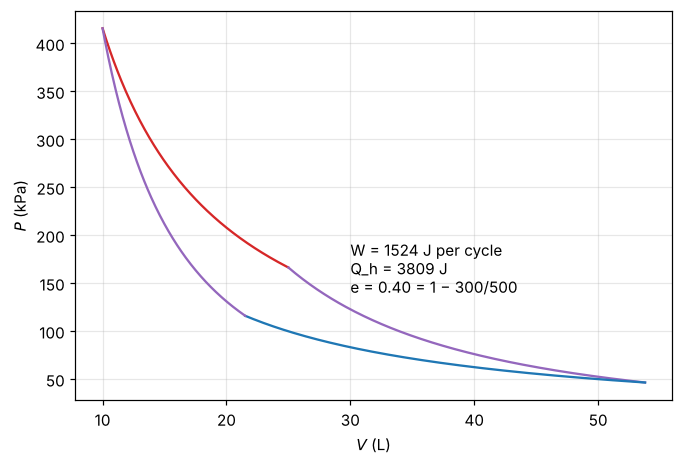

In [2]:
#| label: fig-carnot-cycle
#| caption: "A Carnot cycle for 1 mol of monatomic gas between 500 K and 300 K. Top edge, isothermal expansion at T_h (heat in); right, adiabatic expansion cooling to T_c; bottom, isothermal compression at T_c (heat out); left, adiabatic compression back. The enclosed area is the work per cycle."
R = R_gas; Th, Tc, gam = 500.0, 300.0, 5 / 3
V1, V2 = 0.010, 0.025
V3 = V2 * (Th / Tc)**(1 / (gam - 1)); V4 = V1 * (Th / Tc)**(1 / (gam - 1))
legs = [(V1, V2, lambda V: R * Th / V, "tab:red"), (V2, V3, lambda V: R * Th * V2**(gam - 1) / V**gam, "tab:purple"),
        (V3, V4, lambda V: R * Tc / V, "tab:blue"), (V4, V1, lambda V: R * Th * V1**(gam - 1) / V**gam, "tab:purple")]
fig, ax = plt.subplots()
for a_, b_, P, col in legs:
    V = np.linspace(a_, b_, 200); ax.plot(V * 1e3, P(V) / 1e3, color=col)
W = R * (Th - Tc) * np.log(V2 / V1); Qh = R * Th * np.log(V2 / V1)
ax.text(30, 140, f"W = {W:.0f} J per cycle\nQ_h = {Qh:.0f} J\ne = {W / Qh:.2f} = 1 − 300/500")
ax.set_xlabel("$V$ (L)"); ax.set_ylabel("$P$ (kPa)"); plt.show()

## Refrigerators and Heat Pumps

Run the engine backward: work $W$ moves heat $Q_c$ out of a cold place and dumps $Q_h = Q_c + W$ into a hot one. The figures of merit are coefficients of performance:

$$
\text{COP}_{\text{fridge}} = \frac{Q_c}{W}\le\frac{T_c}{T_h - T_c},\qquad
\text{COP}_{\text{heat pump}} = \frac{Q_h}{W}\le\frac{T_h}{T_h - T_c} .
$$ (eq-cop)

The same entropy argument gives both bounds (the inequality flips because now the cold reservoir loses entropy). Both can exceed 1: a heat pump warming a 20 °C house from 0 °C outside can, in principle, deliver $293/20\approx15$ joules of heat per joule of electricity. Real heat pumps manage 3 to 4, still far better than burning anything.

## Real Cycles: Otto and Diesel

A gasoline engine runs roughly an **Otto cycle**: adiabatic compression of the fuel–air mix by a ratio $r = V_1/V_2$, sudden ignition (heat added at constant volume), adiabatic power stroke, then exhaust (heat expelled at constant volume).

In [3]:
# Otto efficiency, symbolically: heat in and out along the two constant-volume legs
r, g, T1, T3 = sp.symbols("r gamma T_1 T_3", positive=True)
T2 = T1 * r**(g - 1)          # after adiabatic compression
T4 = T3 / r**(g - 1)          # after adiabatic expansion
e = sp.powsimp(sp.simplify(1 - (T4 - T1) / (T3 - T2)), force=True)     # Q_c/Q_h = C_V(T4-T1)/C_V(T3-T2)
display(Math(r"e_{\rm Otto} = " + sp.latex(e)))

<IPython.core.display.Math object>

$$
e_{\text{Otto}} = 1 - \frac{1}{r^{\gamma - 1}} .
$$ (eq-otto)

Higher compression is better, but too high and the mix ignites on its own before the spark ("knock"), which caps gasoline engines at $r\approx10$–12. The **Diesel cycle** avoids the problem by compressing air alone and injecting fuel at the top (topic 2 found air at 1000 K for $r = 20$), so it can run at $r\approx20$ and is more efficient.

Notice what is *not* in {eq}`eq-otto`: the temperatures. The Otto cycle absorbs heat over a range of temperatures (from $T_2$ to $T_3$), not at the peak, and that is why it falls below the Carnot value for its hottest and coldest points.

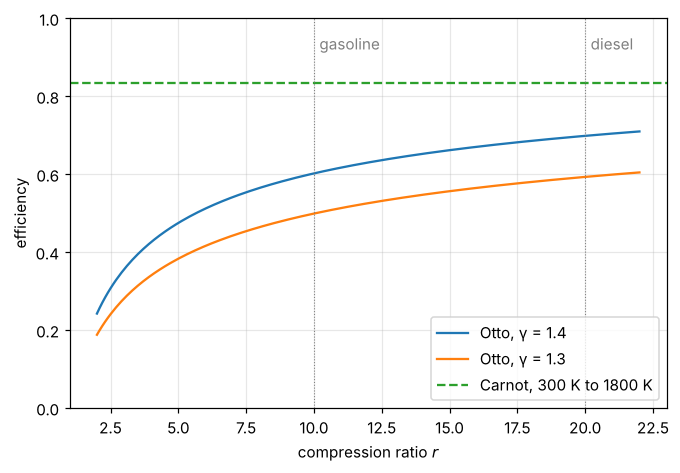

In [4]:
#| label: fig-otto-efficiency
#| caption: "Otto efficiency versus compression ratio for γ = 1.4 (cold air), 1.3 (a hot fuel–air mixture, closer to real) and the Carnot limit between the cycle's extreme temperatures for T₁ = 300 K and a 1800 K peak (green, dashed). The lower γ of a real hot gas costs about 10 percentage points; friction, heat loss and finite combustion time cost more, so real engines reach 30–40%."
rr = np.linspace(2, 22, 200)
fig, ax = plt.subplots()
for gg, col in [(1.4, "tab:blue"), (1.3, "tab:orange")]:
    ax.plot(rr, 1 - rr**(1 - gg), color=col, label=f"Otto, γ = {gg}")
ax.axhline(1 - 300 / 1800, color="tab:green", ls="--", label="Carnot, 300 K to 1800 K")
for rg, lab in [(10, "gasoline"), (20, "diesel")]:
    ax.axvline(rg, color="gray", lw=0.7, ls=":"); ax.text(rg + 0.2, 0.92, lab, color="gray")
ax.set_xlabel("compression ratio $r$"); ax.set_ylabel("efficiency"); ax.set_ylim(0, 1); ax.legend(loc="lower right"); plt.show()

::::{prf:example} Level 2 rung: an Otto cycle with a temperature-dependent heat capacity
:label: ex-otto-real-gas

At high temperatures, vibrations of N₂ and O₂ start to contribute (topic 1's heat-capacity curve), so $C_V$ rises and $\gamma$ falls during the hot part of the cycle. Model air's molar heat capacity as $C_V(T) = \tfrac52R + R\,\dfrac{x^2e^x}{(e^x - 1)^2}$ with $x = \Theta/T$, $\Theta = 3000$ K, and compute the Otto efficiency for $r = 10$, $T_1 = 300$ K and a peak $T_3 = 2200$ K.

:::{dropdown} Solution
Along an adiabat, $C_V\,dT = -P\,dV = -RT\,dV/V$, so $dT/dV = -RT/(C_V(T)V)$: integrate this ODE numerically for each adiabat. Heat in is $\int_{T_2}^{T_3}C_V\,dT$ and heat out is $\int_{T_1}^{T_4}C_V\,dT$. The code below finds $e\approx 0.54$, compared with $0.60$ for constant $\gamma = 1.4$: the extra heat capacity at high temperature stores energy that the expansion stroke recovers less efficiently.
:::
::::

In [5]:
Theta = 3000.0
def Cv(T):
    x = Theta / T
    return 2.5 * R + R * x**2 * np.exp(x) / np.expm1(x)**2
def adiabat(T0, Va, Vb):
    sol = solve_ivp(lambda V, T: -R * T / (Cv(T) * V), (Va, Vb), [T0], rtol=1e-10, atol=1e-8)
    return sol.y[0, -1]
r_, T1_, T3_ = 10.0, 300.0, 2200.0
T2_ = adiabat(T1_, 1.0, 1 / r_)
T4_ = adiabat(T3_, 1 / r_, 1.0)
Qin, _ = quad(Cv, T2_, T3_); Qout, _ = quad(Cv, T1_, T4_)
display(Math(rf"T_2 = {T2_:.0f}\ \text{{K}},\quad T_4 = {T4_:.0f}\ \text{{K}},\quad e = 1 - Q_c/Q_h = {1 - Qout / Qin:.3f}"))
display(Math(rf"\text{{constant }}\gamma = 1.4:\quad e = {1 - r_**(-0.4):.3f}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## How Much Work Can You Get? Finite Reservoirs

Real hot and cold sources are not infinite: a cup of coffee cools as you extract work from it.

::::{prf:example} Maximum work from two finite bodies
:label: ex-max-work-finite

Two identical blocks with constant heat capacity $C$ start at $T_h$ and $T_c$. An ideal (reversible) engine runs between them until they reach a common temperature $T_f$. Find $T_f$ and the total work.

:::{dropdown} Solution
Reversibility means zero total entropy change:

$$
C\ln\frac{T_f}{T_h} + C\ln\frac{T_f}{T_c} = 0\quad\Rightarrow\quad T_f = \sqrt{T_hT_c} .
$$

Energy conservation: $W = C(T_h - T_f) - C(T_f - T_c) = C\left(\sqrt{T_h} - \sqrt{T_c}\right)^2$.

Simply touching the blocks together (no engine) gives $T_f = (T_h + T_c)/2$, higher than $\sqrt{T_hT_c}$: the energy difference is exactly the work that the irreversible contact threw away.
:::
::::

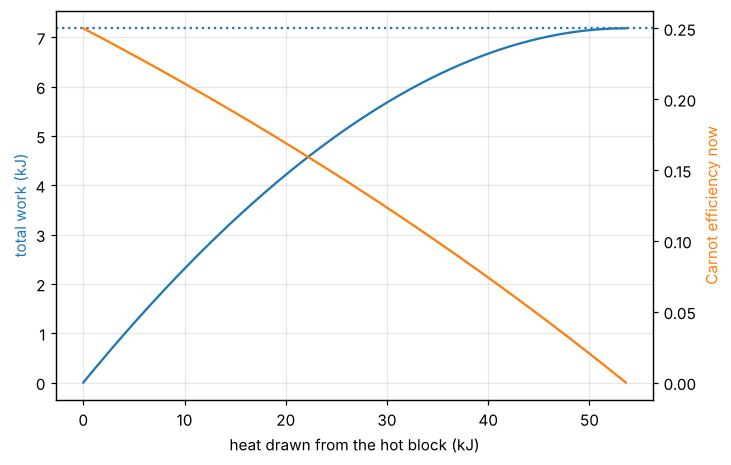

<IPython.core.display.Math object>

In [6]:
#| label: fig-finite-reservoirs
#| caption: "A reversible engine running between two 1 kJ/K blocks starting at 400 K and 300 K. As the blocks approach each other, the instantaneous Carnot efficiency (orange) falls toward zero, so the last bits of heat are nearly worthless. Total work (blue) saturates at C(√T_h − √T_c)² = 7.2 kJ, reached when both blocks are at √(T_hT_c) = 346 K."
C = 1000.0; Th0, Tc0 = 400.0, 300.0
def rhs(t, y):                 # y = [Th, Tc, W]; t is heat drawn from the hot block (J)
    Th_, Tc_, _ = y
    e_ = 1 - Tc_ / Th_
    return [-1 / C, (1 - e_) / C, e_]
def meet(t, y):
    return y[0] - y[1] - 1e-3
meet.terminal = True
sol = solve_ivp(rhs, (0, 60000), [Th0, Tc0, 0], max_step=50, events=meet)
Qh = sol.t; Th_, Tc_, W = sol.y
fig, ax1 = plt.subplots()
ax1.plot(Qh / 1e3, W / 1e3, color="tab:blue"); ax1.set_ylabel("total work (kJ)", color="tab:blue")
ax1.axhline(C * (np.sqrt(Th0) - np.sqrt(Tc0))**2 / 1e3, color="tab:blue", ls=":")
ax2 = ax1.twinx(); ax2.plot(Qh / 1e3, 1 - Tc_ / Th_, color="tab:orange"); ax2.set_ylabel("Carnot efficiency now", color="tab:orange"); ax2.grid(False)
ax1.set_xlabel("heat drawn from the hot block (kJ)"); plt.show()
display(Math(rf"T_f = {Th_[-1]:.1f}\ \text{{K}}\ (\sqrt{{T_hT_c}} = {np.sqrt(Th0 * Tc0):.1f}),\quad W = {W[-1]:.0f}\ \text{{J}}"))

## Looking Ahead to Level 3

The second law is statistical, so at the scale of molecular machines it holds only on average. **Fluctuation theorems** (Jarzynski, Crooks) make this precise: for a small system driven between two states, individual runs can do *less* work than the free-energy difference, but $\langle e^{-W/kT}\rangle = e^{-\Delta F/kT}$ exactly. These go beyond Pathria in places but build on its ensembles.

## Exercises

### Exercises

1. A power plant runs between steam at 550 °C and river water at 20 °C. Find its Carnot efficiency. Its actual efficiency is 40%; for 1 GW of electrical output, how much heat goes into the river?
2. A refrigerator keeps its interior at 3 °C in a 23 °C kitchen. What is the maximum COP? If it removes 300 W of heat, what is the minimum electrical power?
3. Show that for a Carnot cycle in an ideal gas, $V_3/V_4 = V_2/V_1$ (label the corners 1→2 hot isotherm, 2→3 adiabat, 3→4 cold isotherm, 4→1 adiabat).
4. Find the Otto efficiency for $r = 8$ with $\gamma = 1.4$, and the compression ratio needed to reach 60%.
5. Two 1 kg blocks of water (4.19 kJ/K each), at 80 °C and 20 °C. Find the maximum work, and compare with the heat that flows if you just put them in contact.

:::{dropdown} Hints
1. Convert to kelvin. River heat $= Q_h - W$ with $Q_h = W/e$.
2. {eq}`eq-cop`.
3. Use $TV^{\gamma-1}$ = const on each adiabat.
4. {eq}`eq-otto`; then solve $r^{-0.4} = 0.4$.
5. $W = C(\sqrt{T_h} - \sqrt{T_c})^2$ in kelvin.
:::

:::{dropdown} Answers
1. $e_C = 1 - 293/823 = 0.64$. With $e = 0.4$: $Q_h = 2.5$ GW, so 1.5 GW goes to the river.
2. COP $\le 276/20 = 13.8$; minimum power $300/13.8 = 22$ W. Real units draw several times that.
3. $T_hV_2^{\gamma-1} = T_cV_3^{\gamma-1}$ and $T_hV_1^{\gamma-1} = T_cV_4^{\gamma-1}$; divide.
4. $e = 1 - 8^{-0.4} = 0.565$; for 60%, $r = 0.4^{-2.5} = 9.9$.
5. $W = 4190(\sqrt{353.15} - \sqrt{293.15})^2 = 11.7$ kJ. Contact transfers $4190\times30 = 126$ kJ of heat and does no work.
:::

## Summary

- Engine efficiency $e = W/Q_h\le1 - T_c/T_h$, because heat brings entropy that only waste heat can carry out.
- Refrigerator COP $\le T_c/(T_h - T_c)$, heat pump COP $\le T_h/(T_h - T_c)$; both can exceed 1.
- Otto: $e = 1 - r^{1-\gamma}$; Diesel runs at higher $r$. Heat absorbed below the peak temperature, a real gas's falling $\gamma$, and friction all keep real engines well under Carnot.
- With finite reservoirs, maximum work comes from a reversible process, and the final temperature is set by $\Delta S = 0$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.